# Phase 1 — CNN Tomato Disease Classifier

This notebook trains an **EfficientNet-B0** model to classify tomato leaf images into 12 classes.

### Dataset
The dataset is stored as `tomato-files.zip` in Google Drive and contains:

- `train/`
- `valid/`

### Training approach
- ImageNet-pretrained EfficientNet-B0
- 12-class output layer
- Data augmentation for training images
- Weighted sampling for class imbalance
- Phase A: frozen backbone
- Phase B: full fine-tuning
- Early stopping
- Validation accuracy, precision, recall and F1-score
- Confusion matrix
- Training history and plots

The main model is saved as:

`outputs/best_model.pt`

The notebook also copies the results to Google Drive so they are not lost when the Colab runtime resets.

## 1. Imports and Environment

Run this cell first. It defines all libraries, reproducibility settings, the GPU/CPU device, and the main training configuration.

**Important:** If Colab reports `Using device: cpu`, enable a GPU under **Runtime → Change runtime type → T4 GPU** before training.

In [2]:
# ============================================================
# Imports and environment
# ============================================================

import io
import json
import random
import shutil
import time
import warnings
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim

from PIL import Image
from sklearn.metrics import classification_report, confusion_matrix
from torch.utils.data import DataLoader, Dataset, WeightedRandomSampler
from torchvision import transforms
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Reproducibility
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", DEVICE)

if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        f"VRAM: "
        f"{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB"
    )
else:
    print("WARNING: GPU is not enabled.")
    print("Enable a GPU before starting training.")

# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

IMAGE_SIZE = 224
BATCH_SIZE = 32
NUM_WORKERS = 2

PHASE_A_EPOCHS = 5
PHASE_A_LR = 1e-3

PHASE_B_EPOCHS = 25
PHASE_B_LR = 1e-4
PHASE_B_PATIENCE = 5

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

DATA_ROOT = Path("/content")
ZIP_FILE = Path("/content/drive/MyDrive/tomato-files.zip")

SAVE_DIR = Path("/content/outputs")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT = SAVE_DIR / "best_model.pt"

print("\nConfiguration ready.")
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)
print("Workers:", NUM_WORKERS)

Using device: cuda
GPU: Tesla T4
VRAM: 15.6 GB

Configuration ready.
Image size: 224
Batch size: 32
Workers: 2


## 2. Connect Google Drive

The ZIP file is kept in Google Drive so it does not need to be uploaded to Colab every time the notebook is opened.

In [3]:
# ============================================================
# Mount Google Drive
# ============================================================

from google.colab import drive

drive.mount("/content/drive")

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


## 3. Check the Dataset ZIP

The expected file is:

`/content/drive/MyDrive/tomato-files.zip`

If it exists, the notebook displays its size.

In [4]:
# ============================================================
# Check ZIP file
# ============================================================

if not ZIP_FILE.exists():
    raise FileNotFoundError(
        f"Dataset ZIP was not found at: {ZIP_FILE}\n"
        "Make sure tomato-files.zip is in the root of your Google Drive."
    )

zip_size_gb = ZIP_FILE.stat().st_size / 1e9

print("ZIP file found:", ZIP_FILE)
print(f"ZIP size: {zip_size_gb:.2f} GB")

ZIP file found: /content/drive/MyDrive/tomato-files.zip
ZIP size: 1.47 GB


## 4. Extract the Dataset

The dataset is extracted into the Colab runtime.

The cell is **safe to rerun**: if `/content/train` and `/content/valid` already exist, extraction is skipped.

In [5]:
# ============================================================
# Extract dataset
# ============================================================

train_existing = DATA_ROOT / "train"
valid_existing = DATA_ROOT / "valid"

if train_existing.is_dir() and valid_existing.is_dir():
    print("Dataset already extracted.")
    print("Skipping extraction.")
else:
    print(f"Extracting: {ZIP_FILE}")

    with zipfile.ZipFile(ZIP_FILE, "r") as z:
        z.extractall(DATA_ROOT)

    print("Extraction complete.")

print("\nTop-level directories:")
for item in sorted(DATA_ROOT.iterdir()):
    if item.is_dir():
        print("  ", item.name)

Extracting: /content/drive/MyDrive/tomato-files.zip
Extraction complete.

Top-level directories:
   .config
   drive
   outputs
   sample_data
   train
   valid


## 5. Locate and Validate Train/Validation Folders

The current dataset is expected to contain:

- `/content/train`
- `/content/valid`

The validation folder is used for model selection and final evaluation in this notebook.

In [6]:
# ============================================================
# Locate train and validation directories
# ============================================================

def find_split_dirs(root: Path):
    candidates = [root]

    if root.exists():
        candidates.extend(
            item for item in root.iterdir() if item.is_dir()
        )

    for candidate in candidates:
        if not candidate.is_dir():
            continue

        children = {
            item.name.lower()
            for item in candidate.iterdir()
            if item.is_dir()
        }

        if "train" not in children:
            continue

        if "valid" in children:
            val_name = "valid"
        elif "val" in children:
            val_name = "val"
        elif "test" in children:
            val_name = "test"
        else:
            continue

        return candidate / "train", candidate / val_name

    raise FileNotFoundError(
        f"Could not find train/ and valid/val/test folders under {root}."
    )


train_dir, val_dir = find_split_dirs(DATA_ROOT)

print("Train directory:", train_dir)
print("Validation directory:", val_dir)

if not train_dir.is_dir():
    raise FileNotFoundError(f"Train directory does not exist: {train_dir}")

if not val_dir.is_dir():
    raise FileNotFoundError(f"Validation directory does not exist: {val_dir}")

Train directory: /content/train
Validation directory: /content/valid


## 6. Define the 12 Disease Classes

The extracted dataset contains **12 classes**. The class order below is important because it determines the integer label used by the neural network.

| Label | Class |
|---:|---|
| 0 | Bacterial Spot |
| 1 | Early Blight |
| 2 | Late Blight |
| 3 | Leaf Mold |
| 4 | Septoria Leaf Spot |
| 5 | Spider Mites |
| 6 | Two-Spotted Spider Mite |
| 7 | Target Spot |
| 8 | Tomato Yellow Leaf Curl Virus |
| 9 | Tomato Mosaic Virus |
| 10 | Healthy |
| 11 | Powdery Mildew |

In [7]:
# ============================================================
# 11-class configuration
# ============================================================

DISEASE_CLASSES = [
    "Bacterial Spot",
    "Early Blight",
    "Late Blight",
    "Leaf Mold",
    "Septoria Leaf Spot",
    "Spider Mites / Two-Spotted Spider Mite",
    "Target Spot",
    "Tomato Yellow Leaf Curl Virus",
    "Tomato Mosaic Virus",
    "Healthy",
    "Powdery Mildew",
]

NUM_CLASSES = len(DISEASE_CLASSES)

FOLDER_TO_CLASS = {
    "Bacterial_spot": "Bacterial Spot",
    "Early_blight": "Early Blight",
    "Late_blight": "Late Blight",
    "Leaf_Mold": "Leaf Mold",
    "Septoria_leaf_spot": "Septoria Leaf Spot",

    # Your dataset contains these as ONE folder/class
    "Spider_mites Two-spotted_spider_mite":
        "Spider Mites / Two-Spotted Spider Mite",

    "Target_Spot": "Target Spot",
    "Tomato_Yellow_Leaf_Curl_Virus":
        "Tomato Yellow Leaf Curl Virus",
    "Tomato_mosaic_virus": "Tomato Mosaic Virus",
    "healthy": "Healthy",
    "powdery_mildew": "Powdery Mildew",
}

print(f"Number of classes: {NUM_CLASSES}")

for i, cls in enumerate(DISEASE_CLASSES):
    print(f"  {i}: {cls}")

Number of classes: 11
  0: Bacterial Spot
  1: Early Blight
  2: Late Blight
  3: Leaf Mold
  4: Septoria Leaf Spot
  5: Spider Mites / Two-Spotted Spider Mite
  6: Target Spot
  7: Tomato Yellow Leaf Curl Virus
  8: Tomato Mosaic Virus
  9: Healthy
  10: Powdery Mildew


## 7. Inspect Dataset Folders

This checks that the extracted folder names match the 12-class mapping before any model training starts.

In [8]:
# ============================================================
# Validate class folders and count images
# ============================================================

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

def count_images(folder: Path):
    return sum(
        1 for p in folder.iterdir()
        if p.is_file() and p.suffix in IMAGE_EXTENSIONS
    )

def inspect_split(split_name, split_dir):
    print(f"\n{split_name.upper()}")
    print("=" * 90)

    found_classes = set()

    for folder in sorted(split_dir.iterdir()):
        if not folder.is_dir():
            continue

        n_images = count_images(folder)
        mapped = FOLDER_TO_CLASS.get(folder.name)

        if mapped is None:
            print(f"✗ {folder.name:<45} -> SKIPPED ({n_images} images)")
        else:
            found_classes.add(mapped)
            print(f"✓ {folder.name:<45} -> {mapped:<30} ({n_images} images)")

    missing = set(DISEASE_CLASSES) - found_classes

    if missing:
        raise ValueError(
            f"{split_name} is missing these expected classes: {sorted(missing)}"
        )

inspect_split("train", train_dir)
inspect_split("validation", val_dir)

print("\nDataset folder validation passed.")


TRAIN
✓ Bacterial_spot                                -> Bacterial Spot                 (2826 images)
✓ Early_blight                                  -> Early Blight                   (2455 images)
✓ Late_blight                                   -> Late Blight                    (3113 images)
✓ Leaf_Mold                                     -> Leaf Mold                      (2754 images)
✓ Septoria_leaf_spot                            -> Septoria Leaf Spot             (2882 images)
✓ Spider_mites Two-spotted_spider_mite          -> Spider Mites / Two-Spotted Spider Mite (1747 images)
✓ Target_Spot                                   -> Target Spot                    (1827 images)
✓ Tomato_Yellow_Leaf_Curl_Virus                 -> Tomato Yellow Leaf Curl Virus  (2039 images)
✓ Tomato_mosaic_virus                           -> Tomato Mosaic Virus            (2153 images)
✓ healthy                                       -> Healthy                        (3051 images)
✓ powdery_mildew         

## 8. Dataset Class and Image Transformations

Training images receive augmentation to improve robustness to changes in:

- image size and crop
- orientation
- brightness and contrast
- colour
- small rotations
- JPEG compression

Validation images are **not augmented**. They only receive resizing, cropping and ImageNet normalization.

In [9]:
# ============================================================
# Dataset class — automatically skips corrupted images
# ============================================================

class TomatoDataset(Dataset):

    def __init__(self, root_dir: Path, transform=None):
        self.root_dir = Path(root_dir)
        self.transform = transform

        self.class_to_idx = {
            cls: idx
            for idx, cls in enumerate(DISEASE_CLASSES)
        }

        self.samples = []
        self.corrupted_files = []

        # ----------------------------------------------------
        # Collect valid image files
        # ----------------------------------------------------

        for folder in sorted(self.root_dir.iterdir()):

            if not folder.is_dir():
                continue

            class_name = FOLDER_TO_CLASS.get(folder.name)

            if class_name is None:
                continue

            label = self.class_to_idx[class_name]

            for img_path in sorted(folder.iterdir()):

                if not img_path.is_file():
                    continue

                if img_path.suffix not in IMAGE_EXTENSIONS:
                    continue

                # Check image before adding it
                try:
                    with Image.open(img_path) as img:
                        img.verify()

                    with Image.open(img_path) as img:
                        img.convert("RGB").load()

                    self.samples.append(
                        (img_path, label)
                    )

                except Exception as exc:
                    self.corrupted_files.append(
                        (img_path, str(exc))
                    )

        if not self.samples:
            raise ValueError(
                f"No valid images found in '{self.root_dir}'."
            )

        print(
            f"{self.root_dir.name}: "
            f"{len(self.samples):,} valid images | "
            f"{len(self.corrupted_files):,} corrupted/skipped"
        )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):

        img_path, label = self.samples[idx]

        try:
            image = Image.open(img_path).convert("RGB")

        except Exception as exc:
            raise RuntimeError(
                f"Image became unreadable after dataset validation: "
                f"{img_path} -> {exc}"
            ) from exc

        if self.transform is not None:
            image = self.transform(image)

        return image, label


class RandomJPEGCompression:

    def __init__(self, quality_range=(65, 90)):
        self.quality_range = quality_range

    def __call__(self, img):
        quality = random.randint(*self.quality_range)

        buffer = io.BytesIO()
        img.save(buffer, format="JPEG", quality=quality)
        buffer.seek(0)

        return Image.open(buffer).convert("RGB").copy()


IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(p=0.1),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.3,
        hue=0.1,
    ),
    transforms.RandomRotation(15),
    RandomJPEGCompression(quality_range=(65, 90)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

print("Dataset class and transforms are ready.")

Dataset class and transforms are ready.


Finding Corrupted images

In [10]:
# ============================================================
# Find corrupted images
# ============================================================

from PIL import Image
from pathlib import Path

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}

def find_corrupted_images(split_dir):
    corrupted = []

    for folder in sorted(split_dir.iterdir()):
        if not folder.is_dir():
            continue

        for img_path in sorted(folder.iterdir()):
            if not img_path.is_file():
                continue

            if img_path.suffix not in IMAGE_EXTENSIONS:
                continue

            try:
                # verify() checks that the image file is complete
                with Image.open(img_path) as img:
                    img.verify()

                # Open it again and force the image data to load
                with Image.open(img_path) as img:
                    img.convert("RGB").load()

            except Exception as exc:
                corrupted.append((img_path, str(exc)))

    return corrupted


print("Checking training images...")
train_corrupted = find_corrupted_images(train_dir)

print("Checking validation images...")
val_corrupted = find_corrupted_images(val_dir)

print("\n" + "=" * 70)
print("CORRUPTED IMAGE CHECK")
print("=" * 70)

print(f"Corrupted training images:   {len(train_corrupted)}")
print(f"Corrupted validation images: {len(val_corrupted)}")

if train_corrupted:
    print("\nTraining problems:")
    for path, error in train_corrupted:
        print(f"  {path} -> {error}")

if val_corrupted:
    print("\nValidation problems:")
    for path, error in val_corrupted:
        print(f"  {path} -> {error}")

if not train_corrupted and not val_corrupted:
    print("\n✓ No corrupted images found.")

Checking training images...
Checking validation images...

CORRUPTED IMAGE CHECK
Corrupted training images:   0
Corrupted validation images: 1

Validation problems:
  /content/valid/healthy/HL_(336).png -> Truncated File Read


## 9. Create Datasets and Check Class Distribution

The training set uses a `WeightedRandomSampler` so that classes with fewer images are sampled more often.

We deliberately use **sampling only** for imbalance correction here rather than combining the sampler with class-weighted cross-entropy. Using both can over-correct the imbalance.

In [11]:
# ============================================================
# Recreate datasets after removing corrupted files
# ============================================================

train_dataset = TomatoDataset(
    train_dir,
    transform=train_transform,
)

val_dataset = TomatoDataset(
    val_dir,
    transform=val_transform,
)

print("\nDataset summary")
print("=" * 60)
print(f"Training samples:   {len(train_dataset):,}")
print(f"Validation samples: {len(val_dataset):,}")

if train_dataset.corrupted_files:
    print(
        f"\nSkipped {len(train_dataset.corrupted_files)} "
        "corrupted training images."
    )

if val_dataset.corrupted_files:
    print(
        f"Skipped {len(val_dataset.corrupted_files)} "
        "corrupted validation images."
    )

# ------------------------------------------------------------
# Training class distribution
# ------------------------------------------------------------

train_labels = np.array(
    [label for _, label in train_dataset.samples],
    dtype=np.int64,
)

class_counts = np.bincount(
    train_labels,
    minlength=NUM_CLASSES,
)

print("\nTraining class distribution:")
print("=" * 60)

for i, cls in enumerate(DISEASE_CLASSES):
    print(f"{i:2d}: {cls:<32} {class_counts[i]:>6,}")

print("=" * 60)
print("Total:", f"{class_counts.sum():,}")

if np.any(class_counts == 0):
    missing = [
        DISEASE_CLASSES[i]
        for i, count in enumerate(class_counts)
        if count == 0
    ]
    raise ValueError(f"These classes have zero training images: {missing}")

train: 25,851 valid images | 0 corrupted/skipped
valid: 6,683 valid images | 1 corrupted/skipped

Dataset summary
Training samples:   25,851
Validation samples: 6,683
Skipped 1 corrupted validation images.

Training class distribution:
 0: Bacterial Spot                    2,826
 1: Early Blight                      2,455
 2: Late Blight                       3,113
 3: Leaf Mold                         2,754
 4: Septoria Leaf Spot                2,882
 5: Spider Mites / Two-Spotted Spider Mite  1,747
 6: Target Spot                       1,827
 7: Tomato Yellow Leaf Curl Virus     2,039
 8: Tomato Mosaic Virus               2,153
 9: Healthy                           3,051
10: Powdery Mildew                    1,004
Total: 25,851


## 10. Create Data Loaders

The validation loader keeps a fixed ordering and does not use the weighted sampler.

`pin_memory` is enabled automatically when a CUDA GPU is available.

In [12]:
# ============================================================
# Recreate DataLoaders
# ============================================================

train_labels = np.array(
    [label for _, label in train_dataset.samples],
    dtype=np.int64,
)

class_counts = np.bincount(
    train_labels,
    minlength=NUM_CLASSES,
)

print("Training class distribution:")
print("=" * 70)

for i, cls in enumerate(DISEASE_CLASSES):
    print(f"{i:2d}: {cls:<42} {class_counts[i]:>6,}")

print("=" * 70)
print("Total:", f"{class_counts.sum():,}")

# ------------------------------------------------------------
# Weighted sampler
# ------------------------------------------------------------

class_weights_for_sampling = 1.0 / class_counts

sample_weights = np.array(
    [
        class_weights_for_sampling[label]
        for label in train_labels
    ],
    dtype=np.float64,
)

sampler = WeightedRandomSampler(
    weights=torch.as_tensor(
        sample_weights,
        dtype=torch.double,
    ),
    num_samples=len(train_dataset),
    replacement=True,
)

# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=(DEVICE.type == "cuda"),
)

print("\nDataLoaders recreated successfully.")
print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Training class distribution:
 0: Bacterial Spot                              2,826
 1: Early Blight                                2,455
 2: Late Blight                                 3,113
 3: Leaf Mold                                   2,754
 4: Septoria Leaf Spot                          2,882
 5: Spider Mites / Two-Spotted Spider Mite      1,747
 6: Target Spot                                 1,827
 7: Tomato Yellow Leaf Curl Virus               2,039
 8: Tomato Mosaic Virus                         2,153
 9: Healthy                                     3,051
10: Powdery Mildew                              1,004
Total: 25,851

DataLoaders recreated successfully.
Train batches: 808
Validation batches: 209


## 11. Build EfficientNet-B0

EfficientNet-B0 starts with ImageNet-pretrained weights. Its original classifier is replaced with a **12-class** output layer.

This cell also verifies the number of output classes before training.

In [13]:
# ============================================================
# Build EfficientNet-B0
# ============================================================

def build_model(num_classes=NUM_CLASSES, pretrained=True):
    weights = EfficientNet_B0_Weights.IMAGENET1K_V1 if pretrained else None

    model = efficientnet_b0(weights=weights)

    in_features = model.classifier[1].in_features
    model.classifier[1] = nn.Linear(in_features, num_classes)

    return model


def freeze_backbone(model):
    for name, param in model.named_parameters():
        param.requires_grad = ("classifier" in name)


def unfreeze_all(model):
    for param in model.parameters():
        param.requires_grad = True


model = build_model(
    num_classes=NUM_CLASSES,
    pretrained=True,
).to(DEVICE)

gradcam_target_layer = model.features[-1]

total_params = sum(p.numel() for p in model.parameters())

print("Model: EfficientNet-B0")
print("Output classes:", NUM_CLASSES)
print(f"Total parameters: {total_params:,}")
print("Grad-CAM target layer:", gradcam_target_layer.__class__.__name__)

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 152MB/s]


Model: EfficientNet-B0
Output classes: 11
Total parameters: 4,021,639
Grad-CAM target layer: Conv2dNormActivation


## 12. Training Utilities

These functions handle:

- one training epoch
- validation
- accuracy
- learning-rate scheduling
- early stopping
- checkpoint saving

The checkpoint is saved whenever validation accuracy improves.

In [14]:
# ============================================================
# Training utilities
# ============================================================

def make_grad_scaler():
    if DEVICE.type != "cuda":
        return None

    # Compatible with current PyTorch versions.
    try:
        return torch.amp.GradScaler("cuda")
    except (AttributeError, TypeError):
        return torch.cuda.amp.GradScaler()


def autocast_context():
    if DEVICE.type == "cuda":
        try:
            return torch.amp.autocast("cuda")
        except (AttributeError, TypeError):
            return torch.cuda.amp.autocast()

    # CPU context: no mixed precision.
    from contextlib import nullcontext
    return nullcontext()


def train_one_epoch(model, loader, criterion, optimizer, scaler):
    model.train()

    total_loss = 0.0
    correct = 0
    total = 0

    for batch_idx, (images, labels) in enumerate(loader, start=1):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        if scaler is not None:
            with autocast_context():
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0,
            )

            scaler.step(optimizer)
            scaler.update()
        else:
            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0,
            )

            optimizer.step()

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

        if batch_idx % 20 == 0 or batch_idx == len(loader):
            print(
                f"  Batch {batch_idx}/{len(loader)} | "
                f"Loss: {loss.item():.4f} | "
                f"Accuracy: {100.0 * correct / total:.2f}%",
                end="\r",
            )

    print()

    return total_loss / len(loader), 100.0 * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion):
    model.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        outputs = model(images)
        loss = criterion(outputs, labels)

        total_loss += loss.item()

        predictions = outputs.argmax(dim=1)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    return total_loss / len(loader), 100.0 * correct / total


def run_training_phase(
    model,
    phase_name,
    num_epochs,
    lr,
    patience,
    criterion,
    best_val_acc,
):
    optimizer = optim.AdamW(
        filter(lambda p: p.requires_grad, model.parameters()),
        lr=lr,
        weight_decay=1e-4,
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=num_epochs,
        eta_min=lr * 0.01,
    )

    scaler = make_grad_scaler()

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "lr": [],
    }

    patience_counter = 0

    for epoch in range(1, num_epochs + 1):
        current_lr = scheduler.get_last_lr()[0]

        print()
        print(f"[{phase_name}] Epoch {epoch}/{num_epochs} | LR: {current_lr:.2e}")

        start_time = time.time()

        train_loss, train_acc = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler,
        )

        val_loss, val_acc = evaluate(
            model,
            val_loader,
            criterion,
        )

        scheduler.step()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["lr"].append(current_lr)

        elapsed = time.time() - start_time

        print(
            f"  Train -> Loss: {train_loss:.4f} | "
            f"Acc: {train_acc:.2f}%"
        )
        print(
            f"  Val   -> Loss: {val_loss:.4f} | "
            f"Acc: {val_acc:.2f}%"
        )
        print(f"  Epoch time: {elapsed / 60:.1f} min")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "val_acc": best_val_acc,
                    "epoch": epoch,
                    "phase": phase_name,
                    "num_classes": NUM_CLASSES,
                    "disease_classes": DISEASE_CLASSES,
                    "backbone": "efficientnet_b0",
                    "image_size": IMAGE_SIZE,
                },
                CHECKPOINT,
            )

            print(
                f"  New best checkpoint saved: "
                f"{best_val_acc:.2f}%"
            )
        else:
            patience_counter += 1

            print(
                f"  No improvement "
                f"({patience_counter}/{patience})"
            )

            if patience_counter >= patience:
                print("  Early stopping triggered.")
                break

    return history, best_val_acc


print("Training utilities ready.")

Training utilities ready.


## 13. Phase A — Frozen Backbone Warm-up

The EfficientNet feature extractor is frozen and only the new 12-class classification head is trained.

Because the weighted sampler already handles class imbalance, the loss function uses standard cross-entropy without additional class weighting.

In [15]:
# ============================================================
# Phase A
# ============================================================

print("=" * 60)
print("PHASE A — Frozen Backbone Warm-up")
print("=" * 60)

freeze_backbone(model)

trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {trainable:,}")
print("Training classification head...")

criterion = nn.CrossEntropyLoss()

history_a, best_acc_a = run_training_phase(
    model=model,
    phase_name="Phase A",
    num_epochs=PHASE_A_EPOCHS,
    lr=PHASE_A_LR,
    patience=PHASE_A_EPOCHS + 1,
    criterion=criterion,
    best_val_acc=0.0,
)

print(f"\nPhase A complete.")
print(f"Best validation accuracy: {best_acc_a:.2f}%")

PHASE A — Frozen Backbone Warm-up
Trainable parameters: 14,091
Training classification head...

[Phase A] Epoch 1/5 | LR: 1.00e-03
  Batch 808/808 | Loss: 1.1894 | Accuracy: 66.76%
  Train -> Loss: 1.0694 | Acc: 66.76%
  Val   -> Loss: 0.6920 | Acc: 77.48%
  Epoch time: 5.3 min
  New best checkpoint saved: 77.48%

[Phase A] Epoch 2/5 | LR: 9.05e-04
  Batch 808/808 | Loss: 0.5297 | Accuracy: 73.36%
  Train -> Loss: 0.8115 | Acc: 73.36%
  Val   -> Loss: 0.6100 | Acc: 79.89%
  Epoch time: 5.0 min
  New best checkpoint saved: 79.89%

[Phase A] Epoch 3/5 | LR: 6.58e-04
  Batch 808/808 | Loss: 0.5705 | Accuracy: 74.88%
  Train -> Loss: 0.7654 | Acc: 74.88%
  Val   -> Loss: 0.5819 | Acc: 80.31%
  Epoch time: 5.0 min
  New best checkpoint saved: 80.31%

[Phase A] Epoch 4/5 | LR: 3.52e-04
  Batch 808/808 | Loss: 0.8351 | Accuracy: 75.53%
  Train -> Loss: 0.7427 | Acc: 75.53%
  Val   -> Loss: 0.5832 | Acc: 80.22%
  Epoch time: 4.8 min
  No improvement (1/6)

[Phase A] Epoch 5/5 | LR: 1.05e-04
  

## 14. Phase B — Full Fine-Tuning

The best Phase A checkpoint is loaded first.

Then all EfficientNet-B0 layers are unfrozen and trained with a smaller learning rate. Early stopping prevents unnecessary training when validation accuracy stops improving.

In [16]:
# ============================================================
# Phase B
# ============================================================

print("=" * 60)
print("PHASE B — Full Fine-Tuning")
print("=" * 60)

if not CHECKPOINT.exists():
    raise FileNotFoundError(
        "Phase A did not create a checkpoint. "
        "Check the Phase A output before continuing."
    )

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
)

model.load_state_dict(checkpoint["model_state_dict"])

unfreeze_all(model)

trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Trainable parameters: {trainable:,}")
print("All layers are now trainable.")

history_b, best_acc_b = run_training_phase(
    model=model,
    phase_name="Phase B",
    num_epochs=PHASE_B_EPOCHS,
    lr=PHASE_B_LR,
    patience=PHASE_B_PATIENCE,
    criterion=criterion,
    best_val_acc=best_acc_a,
)

print("\nPhase B complete.")
print(f"Overall best validation accuracy: {best_acc_b:.2f}%")

PHASE B — Full Fine-Tuning
Trainable parameters: 4,021,639
All layers are now trainable.

[Phase B] Epoch 1/25 | LR: 1.00e-04
  Batch 808/808 | Loss: 0.2306 | Accuracy: 86.87%
  Train -> Loss: 0.3868 | Acc: 86.87%
  Val   -> Loss: 0.1806 | Acc: 93.84%
  Epoch time: 5.4 min
  New best checkpoint saved: 93.84%

[Phase B] Epoch 2/25 | LR: 9.96e-05
  Batch 808/808 | Loss: 0.1590 | Accuracy: 93.49%
  Train -> Loss: 0.1912 | Acc: 93.49%
  Val   -> Loss: 0.1357 | Acc: 95.60%
  Epoch time: 5.2 min
  New best checkpoint saved: 95.60%

[Phase B] Epoch 3/25 | LR: 9.84e-05
  Batch 808/808 | Loss: 0.0089 | Accuracy: 95.42%
  Train -> Loss: 0.1352 | Acc: 95.42%
  Val   -> Loss: 0.0917 | Acc: 97.38%
  Epoch time: 5.4 min
  New best checkpoint saved: 97.38%

[Phase B] Epoch 4/25 | LR: 9.65e-05
  Batch 808/808 | Loss: 0.2052 | Accuracy: 97.04%
  Train -> Loss: 0.0905 | Acc: 97.04%
  Val   -> Loss: 0.0888 | Acc: 97.49%
  Epoch time: 5.2 min
  New best checkpoint saved: 97.49%

[Phase B] Epoch 5/25 | LR:

## 15. MobileNetV3-Large Comparison

This section trains a second CNN, **MobileNetV3-Large**, using the same 11-class dataset, preprocessing, weighted sampling and evaluation procedure used for EfficientNet-B0.

The purpose is to compare the two architectures experimentally rather than assume that one is better.

MobileNetV3-Large is designed for efficient inference. TorchVision currently reports about 5.48 million parameters and 0.22 GFLOPs for the pretrained architecture. These are reference architecture statistics; the tomato-disease results below are produced by this experiment. citeturn0search0


### 15.1 Build MobileNetV3-Large

The ImageNet-pretrained MobileNetV3-Large is used for transfer learning. Its final classifier is replaced with an 11-class output layer.


In [17]:
# ============================================================
# Build MobileNetV3-Large
# ============================================================

from torchvision.models import (
    mobilenet_v3_large,
    MobileNet_V3_Large_Weights,
)

MOBILE_CHECKPOINT = SAVE_DIR / "mobilenet_v3_large_best.pt"

def build_mobilenet_v3_large(num_classes=NUM_CLASSES, pretrained=True):
    weights = (
        MobileNet_V3_Large_Weights.DEFAULT
        if pretrained else None
    )

    model = mobilenet_v3_large(weights=weights)

    # MobileNetV3-Large classifier:
    # Linear -> Hardswish -> Dropout -> Linear
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)

    return model

mobilenet_model = build_mobilenet_v3_large()
mobilenet_model = mobilenet_model.to(DEVICE)

total_params = sum(p.numel() for p in mobilenet_model.parameters())
trainable_params = sum(
    p.numel()
    for p in mobilenet_model.parameters()
    if p.requires_grad
)

print("MobileNetV3-Large ready.")
print(f"Total parameters:     {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")


Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 152MB/s]


MobileNetV3-Large ready.
Total parameters:     4,216,123
Trainable parameters: 4,216,123


### 15.2 MobileNetV3-Large Training Configuration

The same two-stage transfer-learning strategy is used:

- Phase A: freeze the feature extractor and train the classifier.
- Phase B: unfreeze all layers and fine-tune the complete model.
- The same training and validation datasets are used.
- The same weighted sampler is used for class imbalance.
- Validation images are not augmented.
- Early stopping is used.


In [18]:
# ============================================================
# MobileNetV3-Large training configuration
# ============================================================

MOBILE_PHASE_A_EPOCHS = 5
MOBILE_PHASE_A_LR = 1e-3

MOBILE_PHASE_B_EPOCHS = 25
MOBILE_PHASE_B_LR = 1e-4
MOBILE_PHASE_B_PATIENCE = 5

print("MobileNetV3-Large configuration ready.")
print(f"Phase A epochs: {MOBILE_PHASE_A_EPOCHS}")
print(f"Phase B epochs: {MOBILE_PHASE_B_EPOCHS}")
print(f"Phase B patience: {MOBILE_PHASE_B_PATIENCE}")


MobileNetV3-Large configuration ready.
Phase A epochs: 5
Phase B epochs: 25
Phase B patience: 5


### 15.3 Dedicated Training Helper

In [19]:
# ============================================================
# Dedicated training helper for model comparison
# ============================================================

def train_comparison_phase(
    model,
    phase_name,
    num_epochs,
    lr,
    patience,
    criterion,
    checkpoint_path,
    best_val_acc=0.0,
):
    optimizer = optim.AdamW(
        [p for p in model.parameters() if p.requires_grad],
        lr=lr,
        weight_decay=1e-4,
    )

    scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=num_epochs,
    )

    scaler = torch.amp.GradScaler(
        "cuda",
        enabled=(DEVICE.type == "cuda"),
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": [],
        "epoch_time": [],
    }

    no_improve = 0

    for epoch in range(num_epochs):
        start_time = time.time()
        current_lr = optimizer.param_groups[0]["lr"]

        model.train()

        running_loss = 0.0
        running_correct = 0
        running_total = 0

        print(
            f"\n[{phase_name}] Epoch {epoch + 1}/{num_epochs} "
            f"| LR: {current_lr:.2e}"
        )

        for batch_idx, (images, labels) in enumerate(
            train_loader,
            start=1,
        ):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)

            with torch.amp.autocast(
                "cuda",
                enabled=(DEVICE.type == "cuda"),
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0,
            )

            scaler.step(optimizer)
            scaler.update()

            running_loss += loss.item() * labels.size(0)
            running_correct += (
                outputs.argmax(1) == labels
            ).sum().item()
            running_total += labels.size(0)

            if batch_idx == len(train_loader):
                batch_acc = (
                    100.0 * running_correct / running_total
                )

                print(
                    f"  Batch {batch_idx}/{len(train_loader)} "
                    f"| Loss: {loss.item():.4f} "
                    f"| Accuracy: {batch_acc:.2f}%"
                )

        train_loss = running_loss / running_total
        train_acc = 100.0 * running_correct / running_total

        model.eval()

        val_loss_sum = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(DEVICE, non_blocking=True)
                labels = labels.to(DEVICE, non_blocking=True)

                with torch.amp.autocast(
                    "cuda",
                    enabled=(DEVICE.type == "cuda"),
                ):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * labels.size(0)
                val_correct += (
                    outputs.argmax(1) == labels
                ).sum().item()
                val_total += labels.size(0)

        val_loss = val_loss_sum / val_total
        val_acc = 100.0 * val_correct / val_total
        epoch_time = time.time() - start_time

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(current_lr)
        history["epoch_time"].append(epoch_time)

        print(
            f"  Train -> Loss: {train_loss:.4f} "
            f"| Acc: {train_acc:.2f}%"
        )
        print(
            f"  Val   -> Loss: {val_loss:.4f} "
            f"| Acc: {val_acc:.2f}%"
        )
        print(
            f"  Epoch time: {epoch_time / 60:.1f} min"
        )

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            no_improve = 0

            torch.save(
                {
                    "model_state_dict": model.state_dict(),
                    "val_accuracy": best_val_acc,
                    "phase": phase_name,
                },
                checkpoint_path,
            )

            print(
                f"  New best checkpoint saved: "
                f"{val_acc:.2f}%"
            )
        else:
            no_improve += 1

            print(
                f"  No improvement "
                f"({no_improve}/{patience})"
            )

        scheduler.step()

        if no_improve >= patience:
            print("  Early stopping triggered.")
            break

    return history, best_val_acc


### 15.4 Phase A — Frozen Backbone

In [20]:
# ============================================================
# MobileNetV3-Large Phase A
# ============================================================

def freeze_mobilenet_backbone(model):
    for param in model.features.parameters():
        param.requires_grad = False

    for param in model.classifier.parameters():
        param.requires_grad = True


def unfreeze_mobilenet_all(model):
    for param in model.parameters():
        param.requires_grad = True


freeze_mobilenet_backbone(mobilenet_model)

trainable = sum(
    p.numel()
    for p in mobilenet_model.parameters()
    if p.requires_grad
)

print("=" * 60)
print("MOBILENETV3-LARGE — PHASE A")
print("=" * 60)
print(f"Trainable parameters: {trainable:,}")

mobile_criterion = nn.CrossEntropyLoss()

mobile_history_a, mobile_best_a = train_comparison_phase(
    model=mobilenet_model,
    phase_name="MobileNetV3-Large Phase A",
    num_epochs=MOBILE_PHASE_A_EPOCHS,
    lr=MOBILE_PHASE_A_LR,
    patience=MOBILE_PHASE_A_EPOCHS + 1,
    criterion=mobile_criterion,
    checkpoint_path=MOBILE_CHECKPOINT,
    best_val_acc=0.0,
)

print("\nMobileNetV3-Large Phase A complete.")
print(f"Best Phase A validation accuracy: {mobile_best_a:.2f}%")


MOBILENETV3-LARGE — PHASE A
Trainable parameters: 1,244,171

[MobileNetV3-Large Phase A] Epoch 1/5 | LR: 1.00e-03
  Batch 808/808 | Loss: 0.6132 | Accuracy: 72.68%
  Train -> Loss: 0.8149 | Acc: 72.68%
  Val   -> Loss: 0.5563 | Acc: 80.80%
  Epoch time: 4.7 min
  New best checkpoint saved: 80.80%

[MobileNetV3-Large Phase A] Epoch 2/5 | LR: 9.05e-04
  Batch 808/808 | Loss: 0.3736 | Accuracy: 81.31%
  Train -> Loss: 0.5396 | Acc: 81.31%
  Val   -> Loss: 0.4543 | Acc: 84.27%
  Epoch time: 4.6 min
  New best checkpoint saved: 84.27%

[MobileNetV3-Large Phase A] Epoch 3/5 | LR: 6.55e-04
  Batch 808/808 | Loss: 0.5396 | Accuracy: 85.24%
  Train -> Loss: 0.4291 | Acc: 85.24%
  Val   -> Loss: 0.3573 | Acc: 87.42%
  Epoch time: 4.6 min
  New best checkpoint saved: 87.42%

[MobileNetV3-Large Phase A] Epoch 4/5 | LR: 3.45e-04
  Batch 808/808 | Loss: 0.1715 | Accuracy: 87.71%
  Train -> Loss: 0.3591 | Acc: 87.71%
  Val   -> Loss: 0.2893 | Acc: 90.08%
  Epoch time: 4.6 min
  New best checkpoint sa

### 15.5 Phase B — Full Fine-Tuning

In [21]:
# ============================================================
# MobileNetV3-Large Phase B
# ============================================================

checkpoint = torch.load(
    MOBILE_CHECKPOINT,
    map_location=DEVICE,
)

mobilenet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

unfreeze_mobilenet_all(mobilenet_model)

trainable = sum(
    p.numel()
    for p in mobilenet_model.parameters()
    if p.requires_grad
)

print("=" * 60)
print("MOBILENETV3-LARGE — PHASE B")
print("=" * 60)
print(f"Trainable parameters: {trainable:,}")
print("All layers are now trainable.")

mobile_history_b, mobile_best_b = train_comparison_phase(
    model=mobilenet_model,
    phase_name="MobileNetV3-Large Phase B",
    num_epochs=MOBILE_PHASE_B_EPOCHS,
    lr=MOBILE_PHASE_B_LR,
    patience=MOBILE_PHASE_B_PATIENCE,
    criterion=mobile_criterion,
    checkpoint_path=MOBILE_CHECKPOINT,
    best_val_acc=mobile_best_a,
)

print("\nMobileNetV3-Large training complete.")
print(f"Overall best validation accuracy: {mobile_best_b:.2f}%")


MOBILENETV3-LARGE — PHASE B
Trainable parameters: 4,216,123
All layers are now trainable.

[MobileNetV3-Large Phase B] Epoch 1/25 | LR: 1.00e-04
  Batch 808/808 | Loss: 0.1487 | Accuracy: 92.58%
  Train -> Loss: 0.2176 | Acc: 92.58%
  Val   -> Loss: 0.1741 | Acc: 94.13%
  Epoch time: 5.0 min
  New best checkpoint saved: 94.13%

[MobileNetV3-Large Phase B] Epoch 2/25 | LR: 9.96e-05
  Batch 808/808 | Loss: 0.2816 | Accuracy: 96.05%
  Train -> Loss: 0.1197 | Acc: 96.05%
  Val   -> Loss: 0.1144 | Acc: 96.54%
  Epoch time: 4.8 min
  New best checkpoint saved: 96.54%

[MobileNetV3-Large Phase B] Epoch 3/25 | LR: 9.84e-05
  Batch 808/808 | Loss: 0.0166 | Accuracy: 97.32%
  Train -> Loss: 0.0825 | Acc: 97.32%
  Val   -> Loss: 0.1103 | Acc: 96.98%
  Epoch time: 4.8 min
  New best checkpoint saved: 96.98%

[MobileNetV3-Large Phase B] Epoch 4/25 | LR: 9.65e-05
  Batch 808/808 | Loss: 0.0355 | Accuracy: 97.96%
  Train -> Loss: 0.0626 | Acc: 97.96%
  Val   -> Loss: 0.0902 | Acc: 97.53%
  Epoch time

### 15.6 Evaluate MobileNetV3-Large

The best MobileNetV3-Large checkpoint is evaluated on the same validation set used for EfficientNet-B0.


In [22]:
# ============================================================
# MobileNetV3-Large evaluation
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)

checkpoint = torch.load(
    MOBILE_CHECKPOINT,
    map_location=DEVICE,
)

mobilenet_model.load_state_dict(
    checkpoint["model_state_dict"]
)

mobilenet_model.eval()

mobile_true = []
mobile_pred = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE, non_blocking=True)

        outputs = mobilenet_model(images)

        predictions = (
            outputs.argmax(1)
            .cpu()
            .numpy()
        )

        mobile_pred.extend(
            predictions.tolist()
        )

        mobile_true.extend(
            labels.numpy().tolist()
        )

mobile_accuracy = accuracy_score(
    mobile_true,
    mobile_pred,
)

mobile_precision, mobile_recall, mobile_f1, _ = (
    precision_recall_fscore_support(
        mobile_true,
        mobile_pred,
        average="macro",
        zero_division=0,
    )
)

mobile_report = classification_report(
    mobile_true,
    mobile_pred,
    target_names=DISEASE_CLASSES,
    digits=4,
    zero_division=0,
)

print("=" * 60)
print("MOBILENETV3-LARGE — FINAL EVALUATION")
print("=" * 60)

print(
    f"Best checkpoint validation accuracy: "
    f"{checkpoint['val_accuracy']:.2f}%"
)

print(
    f"Predictions generated: "
    f"{len(mobile_pred):,}"
)

print(
    f"Accuracy:       "
    f"{mobile_accuracy * 100:.2f}%"
)

print(
    f"Macro Precision: "
    f"{mobile_precision * 100:.2f}%"
)

print(
    f"Macro Recall:    "
    f"{mobile_recall * 100:.2f}%"
)

print(
    f"Macro F1:        "
    f"{mobile_f1 * 100:.2f}%"
)

print("\nClassification Report")
print("=" * 80)
print(mobile_report)

(
    SAVE_DIR /
    "mobilenet_v3_large_classification_report.txt"
).write_text(
    mobile_report,
    encoding="utf-8",
)


MOBILENETV3-LARGE — FINAL EVALUATION
Best checkpoint validation accuracy: 98.70%
Predictions generated: 6,683
Accuracy:       98.71%
Macro Precision: 98.88%
Macro Recall:    98.81%
Macro F1:        98.84%

Classification Report
                                        precision    recall  f1-score   support

                        Bacterial Spot     0.9743    0.9836    0.9789       732
                          Early Blight     0.9795    0.9658    0.9726       643
                           Late Blight     0.9836    0.9823    0.9829       792
                             Leaf Mold     0.9866    0.9986    0.9926       739
                    Septoria Leaf Spot     0.9773    0.9826    0.9799       746
Spider Mites / Two-Spotted Spider Mite     0.9977    0.9954    0.9965       435
                           Target Spot     0.9956    0.9956    0.9956       457
         Tomato Yellow Leaf Curl Virus     1.0000    0.9859    0.9929       498
                   Tomato Mosaic Virus     0.9931  

1202

### 15.7 EfficientNet-B0 vs MobileNetV3-Large

In [24]:
import pandas as pd
import numpy as np

In [25]:
# ============================================================
# Model comparison
# ============================================================

# The EfficientNet-B0 metrics below come from the final
# evaluation section of this notebook.

efficientnet_params = sum(
    p.numel() for p in model.parameters()
)

mobilenet_params = sum(
    p.numel() for p in mobilenet_model.parameters()
)

efficientnet_size_mb = (
    CHECKPOINT.stat().st_size / 1e6
)

mobilenet_size_mb = (
    MOBILE_CHECKPOINT.stat().st_size / 1e6
)

# Your existing EfficientNet evaluation cell should define
# macro_f1. If it does not, this field remains blank rather
# than inventing a value.
efficientnet_macro_f1 = globals().get(
    "macro_f1",
    np.nan,
)

comparison_df = pd.DataFrame([
    {
        "Model": "EfficientNet-B0",
        "Validation Accuracy (%)": best_acc_b,
        "Macro F1 (%)": (
            efficientnet_macro_f1 * 100
            if not np.isnan(efficientnet_macro_f1)
            else np.nan
        ),
        "Parameters": efficientnet_params,
        "Checkpoint Size (MB)": efficientnet_size_mb,
    },
    {
        "Model": "MobileNetV3-Large",
        "Validation Accuracy (%)":
            mobile_accuracy * 100,
        "Macro F1 (%)":
            mobile_f1 * 100,
        "Parameters": mobilenet_params,
        "Checkpoint Size (MB)": mobilenet_size_mb,
    },
])

print("=" * 90)
print("EFFICIENTNET-B0 vs MOBILENETV3-LARGE")
print("=" * 90)

display(comparison_df)

comparison_df.to_csv(
    SAVE_DIR /
    "efficientnet_vs_mobilenet_comparison.csv",
    index=False,
)


EFFICIENTNET-B0 vs MOBILENETV3-LARGE


,Model,Validation Accuracy (%),Macro F1 (%),Parameters,Checkpoint Size (MB)
0,EfficientNet-B0,98.787969,NaN,4021639,16.386553
1,MobileNetV3-Large,98.713153,98.840875,4216123,17.075183


### 15.8 Inference Speed Comparison

This measures inference time on the current Colab runtime.

**Important:** this is a relative benchmark on the current Colab environment. It should not be presented as a smartphone inference benchmark because the phone hardware will be different.


In [26]:
# ============================================================
# Inference speed comparison
# ============================================================

def benchmark_inference(
    model_to_test,
    loader,
    warmup_batches=10,
    test_batches=50,
):
    model_to_test.eval()

    batch_times = []

    with torch.no_grad():
        for batch_idx, (images, _) in enumerate(loader):

            if batch_idx >= (
                warmup_batches +
                test_batches
            ):
                break

            images = images.to(
                DEVICE,
                non_blocking=True,
            )

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            start = time.perf_counter()

            _ = model_to_test(images)

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()

            elapsed = (
                time.perf_counter() -
                start
            )

            if batch_idx >= warmup_batches:
                batch_times.append(elapsed)

    mean_batch_time = float(
        np.mean(batch_times)
    )

    images_per_second = (
        BATCH_SIZE /
        mean_batch_time
    )

    milliseconds_per_image = (
        mean_batch_time /
        BATCH_SIZE
    ) * 1000

    return (
        mean_batch_time,
        images_per_second,
        milliseconds_per_image,
    )


efficientnet_batch, efficientnet_ips, efficientnet_ms = (
    benchmark_inference(
        model,
        val_loader,
    )
)

mobilenet_batch, mobilenet_ips, mobilenet_ms = (
    benchmark_inference(
        mobilenet_model,
        val_loader,
    )
)

speed_df = pd.DataFrame([
    {
        "Model": "EfficientNet-B0",
        "Mean batch time (s)":
            efficientnet_batch,
        "Images/second":
            efficientnet_ips,
        "Milliseconds/image":
            efficientnet_ms,
    },
    {
        "Model": "MobileNetV3-Large",
        "Mean batch time (s)":
            mobilenet_batch,
        "Images/second":
            mobilenet_ips,
        "Milliseconds/image":
            mobilenet_ms,
    },
])

print("=" * 90)
print("INFERENCE SPEED — CURRENT COLAB RUNTIME")
print("=" * 90)

display(speed_df)

speed_df.to_csv(
    SAVE_DIR /
    "efficientnet_vs_mobilenet_inference_speed.csv",
    index=False,
)


INFERENCE SPEED — CURRENT COLAB RUNTIME


,Model,Mean batch time (s),Images/second,Milliseconds/image
0,EfficientNet-B0,0.038218,837.302011,1.194312
1,MobileNetV3-Large,0.026392,1212.477322,0.824758


### 15.9 Final Model Comparison

This table combines predictive performance, model size and the current runtime's inference measurement.

The results should be interpreted together rather than selecting a model using accuracy alone.


In [27]:
# ============================================================
# Final comparison table
# ============================================================

final_comparison = comparison_df.copy()

final_comparison[
    "Mean Inference ms/image"
] = [
    efficientnet_ms,
    mobilenet_ms,
]

display(final_comparison)

final_comparison.to_csv(
    SAVE_DIR /
    "final_model_comparison.csv",
    index=False,
)

print("\nSaved comparison files:")
print(
    "- efficientnet_vs_mobilenet_comparison.csv"
)
print(
    "- efficientnet_vs_mobilenet_inference_speed.csv"
)
print(
    "- final_model_comparison.csv"
)
print(
    "- mobilenet_v3_large_classification_report.txt"
)


,Model,Validation Accuracy (%),Macro F1 (%),Parameters,Checkpoint Size (MB),Mean Inference ms/image
0,EfficientNet-B0,98.787969,NaN,4021639,16.386553,1.194312
1,MobileNetV3-Large,98.713153,98.840875,4216123,17.075183,0.824758



Saved comparison files:
- efficientnet_vs_mobilenet_comparison.csv
- efficientnet_vs_mobilenet_inference_speed.csv
- final_model_comparison.csv
- mobilenet_v3_large_classification_report.txt


## 15. Model Evaluation

The best checkpoint is reloaded and evaluated on the validation set.

The notebook produces:

1. confusion matrix
2. classification report
3. per-class precision, recall and F1-score
4. validation accuracy
5. saved evaluation files

Best checkpoint validation accuracy: 98.79%
Predictions generated: 6,683

Classification Report
                                        precision    recall  f1-score   support

                        Bacterial Spot     0.9903    0.9795    0.9849       732
                          Early Blight     0.9779    0.9642    0.9710       643
                           Late Blight     0.9886    0.9836    0.9861       792
                             Leaf Mold     0.9933    0.9973    0.9953       739
                    Septoria Leaf Spot     0.9620    0.9853    0.9735       746
Spider Mites / Two-Spotted Spider Mite     1.0000    0.9931    0.9965       435
                           Target Spot     0.9913    0.9978    0.9945       457
         Tomato Yellow Leaf Curl Virus     1.0000    0.9960    0.9980       498
                   Tomato Mosaic Virus     0.9965    0.9863    0.9914       584
                               Healthy     0.9901    0.9963    0.9932       805
                       

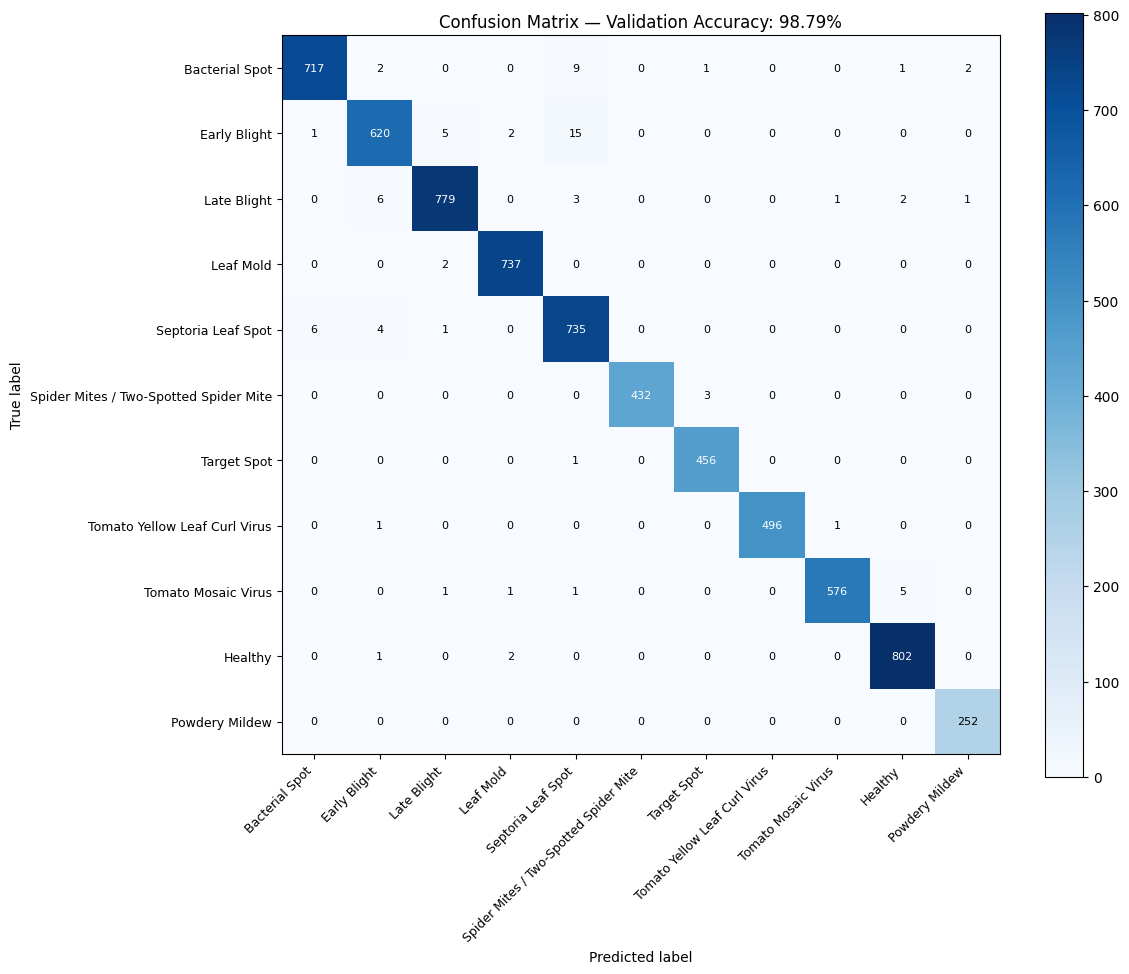

Saved: /content/outputs/confusion_matrix.png


In [28]:
# ============================================================
# Reload best checkpoint
# ============================================================

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE,
)

model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

print(
    f"Best checkpoint validation accuracy: "
    f"{checkpoint['val_acc']:.2f}%"
)

# ------------------------------------------------------------
# Generate predictions
# ------------------------------------------------------------

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE, non_blocking=True)

        outputs = model(images)
        predictions = outputs.argmax(dim=1).cpu().numpy()

        all_preds.extend(predictions.tolist())
        all_labels.extend(labels.numpy().tolist())

all_preds = np.asarray(all_preds)
all_labels = np.asarray(all_labels)

print(f"Predictions generated: {len(all_preds):,}")

# ------------------------------------------------------------
# Classification report
# ------------------------------------------------------------

report = classification_report(
    all_labels,
    all_preds,
    target_names=DISEASE_CLASSES,
    digits=4,
    zero_division=0,
)

print("\nClassification Report")
print("=" * 80)
print(report)

report_path = SAVE_DIR / "classification_report.txt"

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("Saved:", report_path)

# ------------------------------------------------------------
# Confusion matrix
# ------------------------------------------------------------

cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=np.arange(NUM_CLASSES),
)

fig, ax = plt.subplots(figsize=(12, 10))

im = ax.imshow(
    cm,
    interpolation="nearest",
    cmap=plt.cm.Blues,
)

plt.colorbar(im, ax=ax)

tick_marks = np.arange(NUM_CLASSES)

ax.set_xticks(tick_marks)
ax.set_yticks(tick_marks)

ax.set_xticklabels(
    DISEASE_CLASSES,
    rotation=45,
    ha="right",
    fontsize=9,
)

ax.set_yticklabels(
    DISEASE_CLASSES,
    fontsize=9,
)

threshold = cm.max() / 2.0

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=8,
        )

ax.set_ylabel("True label")
ax.set_xlabel("Predicted label")
ax.set_title(
    f"Confusion Matrix — "
    f"Validation Accuracy: {checkpoint['val_acc']:.2f}%"
)

plt.tight_layout()

cm_path = SAVE_DIR / "confusion_matrix.png"

plt.savefig(
    cm_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

print("Saved:", cm_path)

## 16. Training History

The validation accuracy and validation loss from both training phases are combined so that the complete training process can be viewed as one sequence.

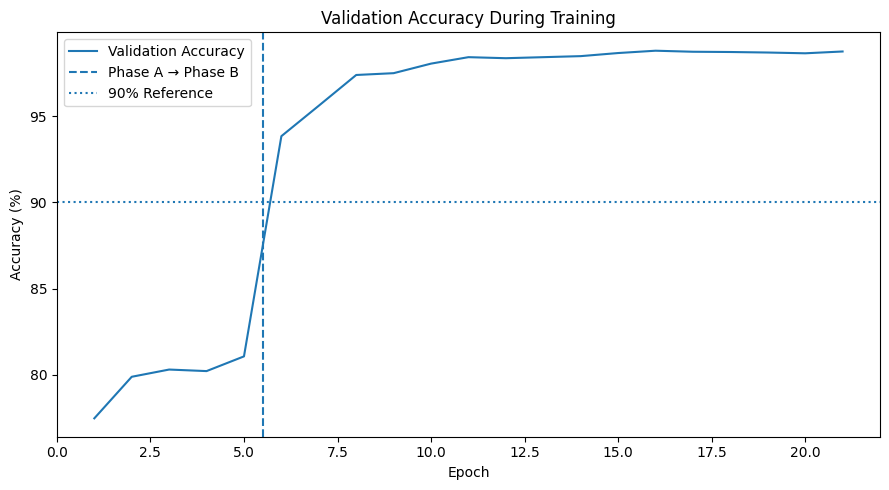

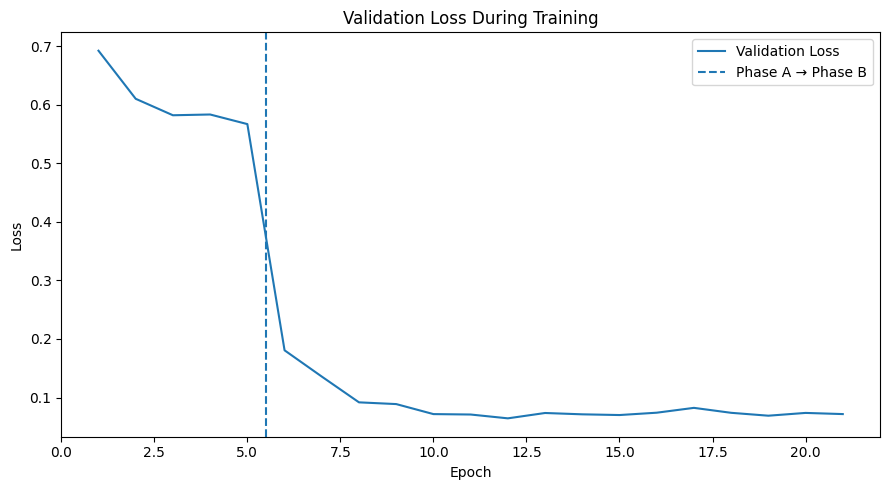

Saved:
  /content/outputs/validation_accuracy.png
  /content/outputs/validation_loss.png
  /content/outputs/training_history.json


In [29]:
# ============================================================
# Training history plots
# ============================================================

combined_val_acc = (
    history_a["val_acc"] +
    history_b["val_acc"]
)

combined_val_loss = (
    history_a["val_loss"] +
    history_b["val_loss"]
)

combined_train_acc = (
    history_a["train_acc"] +
    history_b["train_acc"]
)

combined_train_loss = (
    history_a["train_loss"] +
    history_b["train_loss"]
)

phase_boundary = len(history_a["val_acc"])

# ------------------------------------------------------------
# Validation accuracy
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(combined_val_acc) + 1),
    combined_val_acc,
    label="Validation Accuracy",
)

plt.axvline(
    x=phase_boundary + 0.5,
    linestyle="--",
    label="Phase A → Phase B",
)

plt.axhline(
    y=90,
    linestyle=":",
    label="90% Reference",
)

plt.title("Validation Accuracy During Training")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.tight_layout()

accuracy_path = SAVE_DIR / "validation_accuracy.png"

plt.savefig(
    accuracy_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# Validation loss
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(combined_val_loss) + 1),
    combined_val_loss,
    label="Validation Loss",
)

plt.axvline(
    x=phase_boundary + 0.5,
    linestyle="--",
    label="Phase A → Phase B",
)

plt.title("Validation Loss During Training")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()

loss_path = SAVE_DIR / "validation_loss.png"

plt.savefig(
    loss_path,
    dpi=150,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# Save complete history
# ------------------------------------------------------------

full_history = {
    "phase_a": history_a,
    "phase_b": history_b,
    "best_val_acc": float(best_acc_b),
    "phase_boundary_epoch": int(phase_boundary),
}

history_path = SAVE_DIR / "training_history.json"

with open(history_path, "w", encoding="utf-8") as f:
    json.dump(full_history, f, indent=2)

print("Saved:")
print(" ", accuracy_path)
print(" ", loss_path)
print(" ", history_path)

## 17. Final Training Results

This cell provides a compact summary of the final training run and lists all generated files.

In [30]:
# ============================================================
# Final results
# ============================================================

print("=" * 60)
print("TRAINING COMPLETE")
print("=" * 60)

print(f"\nNumber of classes: {NUM_CLASSES}")
print(f"Training samples: {len(train_dataset):,}")
print(f"Validation samples: {len(val_dataset):,}")
print(f"Best validation accuracy: {best_acc_b:.2f}%")
print(f"Best checkpoint: {CHECKPOINT}")
print(
    f"Model size: "
    f"{CHECKPOINT.stat().st_size / 1e6:.2f} MB"
)

print("\nGenerated files:")

for file in sorted(SAVE_DIR.iterdir()):
    print(
        f"  {file.name:<30} "
        f"{file.stat().st_size / 1e6:.2f} MB"
    )

TRAINING COMPLETE

Number of classes: 11
Training samples: 25,851
Validation samples: 6,683
Best validation accuracy: 98.79%
Best checkpoint: /content/outputs/best_model.pt
Model size: 16.39 MB

Generated files:
  best_model.pt                  16.39 MB
  classification_report.txt      0.00 MB
  confusion_matrix.png           0.17 MB
  efficientnet_vs_mobilenet_comparison.csv 0.00 MB
  efficientnet_vs_mobilenet_inference_speed.csv 0.00 MB
  final_model_comparison.csv     0.00 MB
  mobilenet_v3_large_best.pt     17.08 MB
  mobilenet_v3_large_classification_report.txt 0.00 MB
  training_history.json          0.00 MB
  validation_accuracy.png        0.06 MB
  validation_loss.png            0.05 MB


## 18. Copy Results to Google Drive

Colab runtime storage is temporary. This cell copies the model and evaluation files into:

`MyDrive/tomato_training_outputs/`

This gives you a persistent copy even after the Colab runtime ends.

In [31]:
# ============================================================
# Persist results to Google Drive
# ============================================================

DRIVE_OUTPUT_DIR = Path(
    "/content/drive/MyDrive/tomato_training_outputs"
)

DRIVE_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

for source_file in SAVE_DIR.iterdir():
    if source_file.is_file():
        destination = DRIVE_OUTPUT_DIR / source_file.name
        shutil.copy2(source_file, destination)
        print("Copied:", destination)

print("\nAll training outputs have been copied to:")
print(DRIVE_OUTPUT_DIR)

Copied: /content/drive/MyDrive/tomato_training_outputs/validation_accuracy.png
Copied: /content/drive/MyDrive/tomato_training_outputs/classification_report.txt
Copied: /content/drive/MyDrive/tomato_training_outputs/confusion_matrix.png
Copied: /content/drive/MyDrive/tomato_training_outputs/efficientnet_vs_mobilenet_inference_speed.csv
Copied: /content/drive/MyDrive/tomato_training_outputs/final_model_comparison.csv
Copied: /content/drive/MyDrive/tomato_training_outputs/best_model.pt
Copied: /content/drive/MyDrive/tomato_training_outputs/mobilenet_v3_large_best.pt
Copied: /content/drive/MyDrive/tomato_training_outputs/validation_loss.png
Copied: /content/drive/MyDrive/tomato_training_outputs/efficientnet_vs_mobilenet_comparison.csv
Copied: /content/drive/MyDrive/tomato_training_outputs/training_history.json
Copied: /content/drive/MyDrive/tomato_training_outputs/mobilenet_v3_large_classification_report.txt

All training outputs have been copied to:
/content/drive/MyDrive/tomato_training_

## 19. Download the Most Important Files

The model required by the backend is:

`best_model.pt`

The other files are useful for documenting the model evaluation in the project report.

In [32]:
# ============================================================
# Download model and evaluation files
# ============================================================

from google.colab import files

download_files = [
    CHECKPOINT,
    SAVE_DIR / "classification_report.txt",
    SAVE_DIR / "confusion_matrix.png",
    SAVE_DIR / "validation_accuracy.png",
    SAVE_DIR / "validation_loss.png",
    SAVE_DIR / "training_history.json",
]

for file_path in download_files:
    if file_path.exists():
        print("Downloading:", file_path.name)
        files.download(str(file_path))
    else:
        print("Missing:", file_path)

Downloading: best_model.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: classification_report.txt


<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloading: training_history.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>